# Método de Euler

Autor: Guillermo Hernández Ruiz de Esparza

Asesor: Dr. Edgar Ali Ramos Gómez

Proyecto: Implementación de herramientas computacionales mediante Python para la enseñanza de ecuaciones diferenciales

Facultad de Ingenieria, UNAM

In [174]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

Parámetros

In [175]:
x_0 = 0
x_max = 4
y_0 = np.round(np.pi/3, 4)
h = 0.2

Solución numérica

In [176]:
def f(x, y):
    return 5*np.power(x, 2)*np.sin(3*x)*np.sin(y)

In [177]:
x = [x_0]
y_numerica = [y_0]
i = 0

while x[-1] < x_max:
    x_i = x[i]
    x_siguiente = np.round(x_i + h, 2)
    x.append(x_siguiente)

    y_i = y_numerica[i]
    y_siguiente = y_i + h*f(x_i, y_i)
    y_siguiente = np.round(y_siguiente, 4)
    y_numerica.append(y_siguiente)
    i += 1

Solución analítica

In [178]:
def f_analítica(x):
    return np.arccos(np.tanh(0.037 * (-30 * x * np.sin(3 * x) + 5 * (9 * np.power(x, 2) - 2) * np.cos(3 * x) + 24.831)))

In [179]:
y_real = []

for x_ in x:
    y = f_analítica(x_)
    y = np.round(y, 4)
    y_real.append(y)

Calculo de errores

In [180]:
error_absoluto = []
error_porcentual = []
for y_r, y_n in zip(y_real, y_numerica):
    # Error absoluto
    e_a = np.abs(y_r - y_n)
    e_a = np.round(e_a, 4)
    error_absoluto.append(e_a)

    # Error porcentual
    if y_r != 0:
        e_p = np.abs((y_r - y_n) / y_r) * 100
        e_p = np.round(e_p, 4)
        error_porcentual.append(e_p)
    else:
        error_porcentual.append(np.nan)

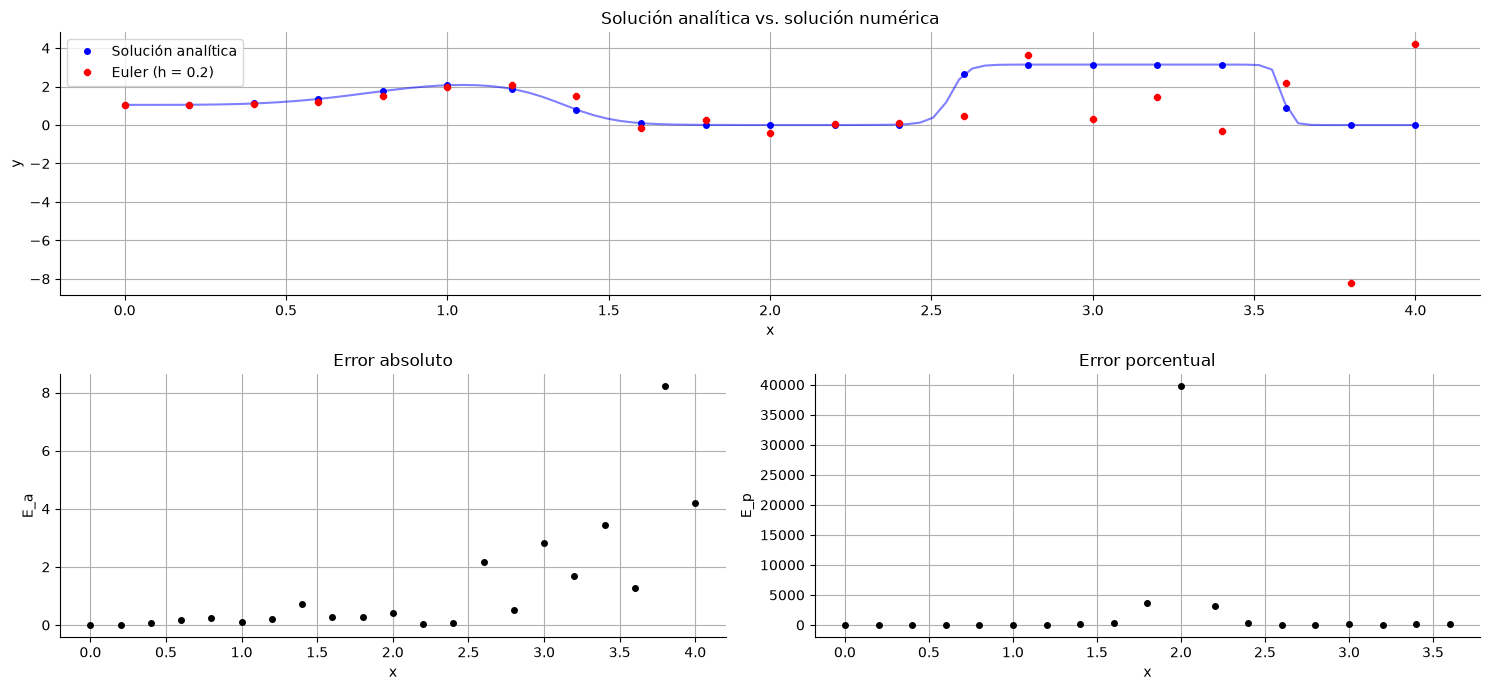

In [181]:
fig = plt.figure(figsize=(15, 7))
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])

ax1.plot(np.linspace(x_0, x_max, 100), [f_analítica(x) for x in np.linspace(x_0, x_max, 100)], color="blue", alpha=0.5)
ax1.plot(x, y_real, label="Solución analítica", color='blue', marker='o', markersize=4, linestyle='None')
ax1.plot(x, y_numerica, label=f"Euler (h = {h})", color="red", marker='8', markersize=4, linestyle='None')
ax1.set_title("Solución analítica vs. solución numérica")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.grid()
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.legend()

ax2.plot(x, error_absoluto, color="black", marker="o", markersize=4, linestyle='None')
ax2.set_title("Error absoluto")
ax2.set_xlabel("x")
ax2.set_ylabel("E_a")
ax2.grid()
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

ax3.plot(x, error_porcentual, color="black", marker="o", markersize=4, linestyle='None')
ax3.set_title("Error porcentual")
ax3.set_xlabel("x")
ax3.set_ylabel("E_p")
ax3.grid()
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f"euler h={h}.png", dpi=300)
plt.show()

In [183]:
df_euler = pd.DataFrame({
    "i": np.arange(len(x)),
    "x": x,
    "y_numerica": y_numerica,
    "y_real": y_real,
    "E_a": error_absoluto,
    "E_p": error_porcentual
})
df_euler.set_index("i", inplace=True)
df_euler.to_csv(f"euler h={h}.csv", index=True)
df_euler

,x,y_numerica,y_real,E_a,E_p
i,,,,,
0,0.0,1.0472,1.0477,0.0005,0.0477
1,0.2,1.0472,1.0527,0.0055,0.5225
2,0.4,1.0668,1.1196,0.0528,4.7160
3,0.6,1.1974,1.3545,0.1571,11.5984
4,0.8,1.5238,1.7636,0.2398,13.5972
5,1.0,1.9556,2.0688,0.1132,5.4718
6,1.2,2.0864,1.8760,0.2104,11.2154
7,1.4,1.5320,0.8045,0.7275,90.4288
8,1.6,-0.1750,0.0967,0.2717,280.9721
